In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

df = pd.read_csv("../data/processed/customers_clean.csv")

LOG_FEATURES = ["Number_of_Orders", "Avg_Order_Value", "Days_Since_Last_Purchase"]
PLAIN_FEATURES = ["Items_Per_Order", "Average_Rating", "Discount_Applied"]
FEATURES = LOG_FEATURES + PLAIN_FEATURES

preprocessor = ColumnTransformer([
    ("log_features", Pipeline([("log", FunctionTransformer(np.log1p)),
                               ("scale", StandardScaler())]), LOG_FEATURES),
    ("plain_features", Pipeline([("impute", SimpleImputer(strategy="median")),
                                 ("scale", StandardScaler())]), PLAIN_FEATURES),
])
X_scaled = preprocessor.fit_transform(df[FEATURES])
print(X_scaled.shape)

(60000, 6)


In [2]:
K_RANGE = range(2, 11)
inertias, sil_scores = [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels, sample_size=10000, random_state=42))
    print(f"K={k}  inertia={km.inertia_:,.0f}  silhouette={sil_scores[-1]:.3f}")

K=2  inertia=256,996  silhouette=0.260
K=3  inertia=208,397  silhouette=0.235
K=4  inertia=175,665  silhouette=0.247
K=5  inertia=160,331  silhouette=0.247
K=6  inertia=145,340  silhouette=0.243
K=7  inertia=134,267  silhouette=0.230
K=8  inertia=126,817  silhouette=0.239
K=9  inertia=119,885  silhouette=0.233
K=10  inertia=113,749  silhouette=0.236


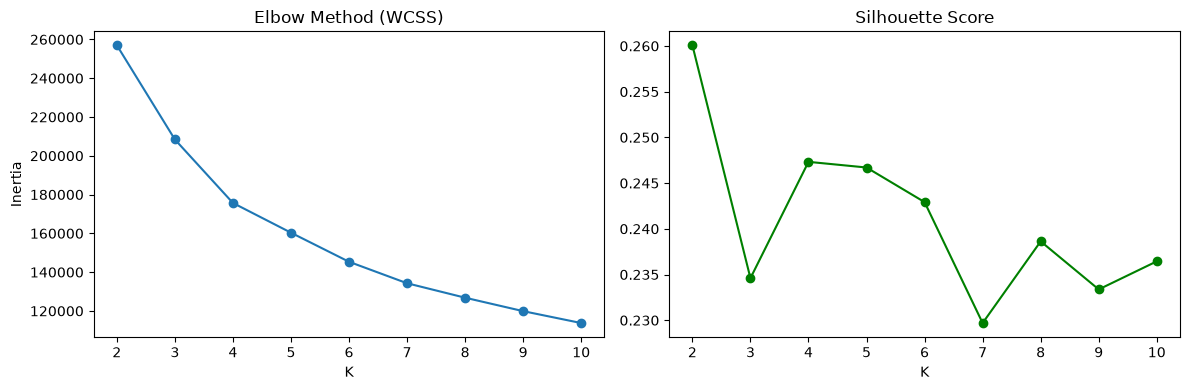

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(K_RANGE), inertias, marker="o")
axes[0].set_title("Elbow Method (WCSS)")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(K_RANGE), sil_scores, marker="o", color="green")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("K")
plt.tight_layout()
plt.show()

In [4]:
table = pd.DataFrame({"K": list(K_RANGE), "inertia": inertias, "silhouette": np.round(sil_scores, 3)})
table["drop_from_previous_K"] = (-table["inertia"].diff()).round(0)
table

,K,inertia,silhouette,drop_from_previous_K
0,2,256995.871056,0.260,NaN
1,3,208396.750479,0.235,48599.0
2,4,175664.694791,0.247,32732.0
3,5,160330.974200,0.247,15334.0
4,6,145339.899228,0.243,14991.0
5,7,134266.893025,0.230,11073.0
6,8,126817.428132,0.239,7449.0
7,9,119885.347520,0.233,6932.0
8,10,113748.749407,0.236,6137.0


Information kept by the 2 PCA axes: 0.62
K=3 cluster shares: [0.28, 0.47, 0.25]
K=4 cluster shares: [0.23, 0.35, 0.2, 0.23]
K=5 cluster shares: [0.2, 0.32, 0.19, 0.15, 0.14]


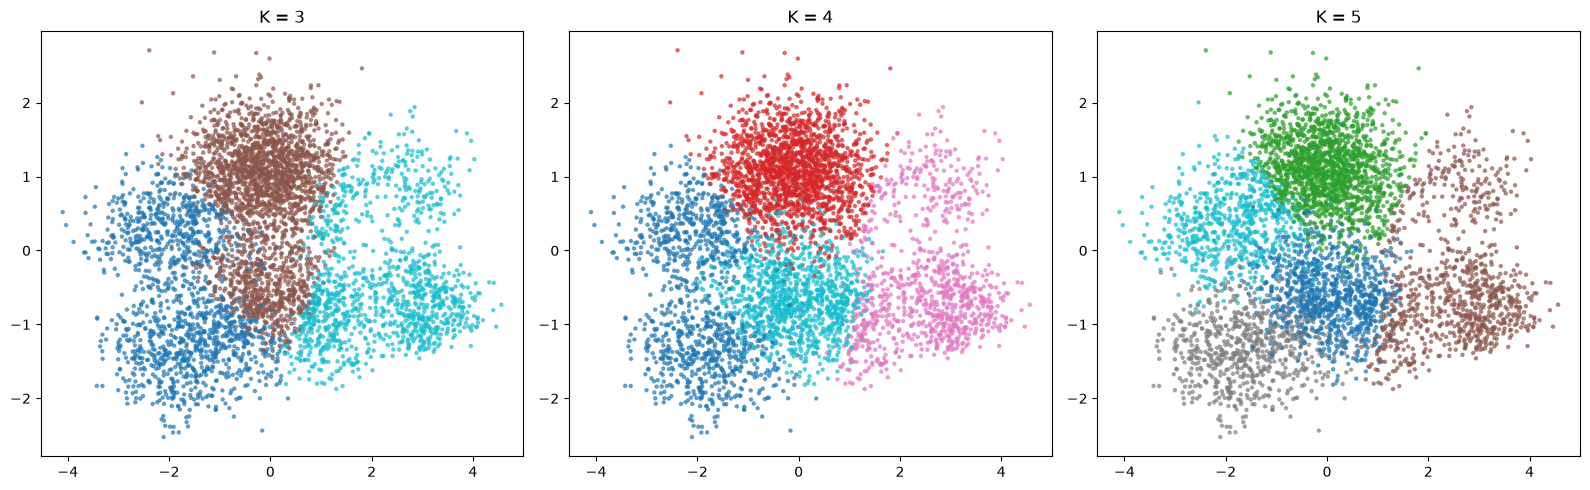

In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
print("Information kept by the 2 PCA axes:", pca.explained_variance_ratio_.sum().round(2))

sample_idx = np.random.default_rng(42).choice(len(X_scaled), 5000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, k in zip(axes, [3, 4, 5]):
    labels = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit_predict(X_scaled)
    ax.scatter(coords[sample_idx, 0], coords[sample_idx, 1],
               c=labels[sample_idx], s=5, cmap="tab10", alpha=0.6)
    ax.set_title(f"K = {k}")
    print(f"K={k} cluster shares:", pd.Series(labels).value_counts(normalize=True).sort_index().round(2).tolist())

plt.tight_layout()
plt.show()